# 03 · Análise Exploratória (EDA) com foco em negócio

Esta análise foi escrita pensando em **um(a) gerente de operações que não precisa entender estatística**. Por isso, em vez de coeficientes, falamos em:

- **Nota média**: a média das notas de 0 a 10;
- **% de detratores**: de cada 100 clientes, quantos deram nota abaixo de 7;
- **NPS**: % de promotores menos % de detratores (de −100 a +100).

Perguntas que guiam o notebook (etapa 3 do desafio):

1. Quais fatores parecem mais críticos para a satisfação?
2. O que mais gera detratores?
3. Existe algum "ponto de ruptura" na experiência?
4. Que tipo de cliente tende a ter NPS mais alto ou mais baixo?

Ao longo do caminho, testamos as **hipóteses H1 a H5** registradas no notebook 01. Os testes estatísticos aparecem apenas para confirmar o que os gráficos sugerem, sempre com a hipótese nula (H₀) escrita por extenso. Todos os gráficos são salvos em `reports/figures/`.

In [1]:
import sys
from pathlib import Path

sys.path.append(str(Path.cwd().parent))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats
from statsmodels.stats.proportion import proportion_confint

from src.funcoes_nps import (
    COLUNAS_POS_PESQUISA, COLUNAS_PRE_PESQUISA, NOMES_AMIGAVEIS, calcular_nps,
    carregar_dados_tratados, intervalo_confianca_nps_bootstrap, resumir_nps_por_grupo,
)
from src.graficos import (
    COR_AZUL, COR_CINZA, COR_CINZA_CLARO, COR_VERMELHA, CORES_CATEGORIA_NPS,
    configurar_estilo, rotular_barras, salvar_figura,
)

configurar_estilo()
dados = carregar_dados_tratados()
print(f"{len(dados)} pedidos carregados")

2500 pedidos carregados


## 1. O ponto de partida: como está a satisfação hoje?

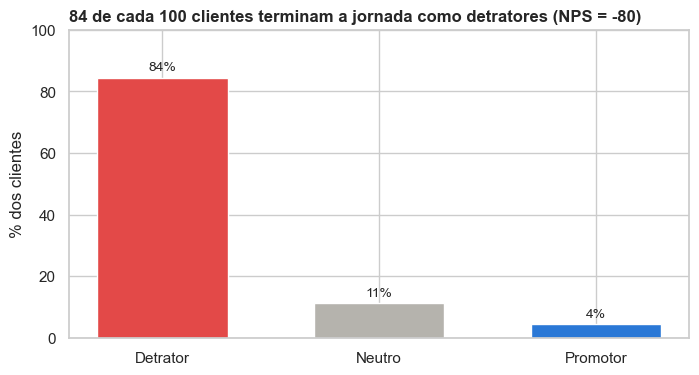

In [2]:
participacao = dados["categoria_nps"].value_counts(normalize=True).sort_index() * 100
nps_da_base = calcular_nps(dados["nps_score"])

figura, eixo = plt.subplots(figsize=(8, 4))
eixo.bar(participacao.index, participacao.values, color=[CORES_CATEGORIA_NPS[c] for c in participacao.index], width=0.6)
rotular_barras(eixo, sufixo="%")
eixo.set_title(f"84 de cada 100 clientes terminam a jornada como detratores (NPS = {nps_da_base:.0f})")
eixo.set_ylabel("% dos clientes")
eixo.set_ylim(0, 100)
salvar_figura(figura, "01_distribuicao_nps.png")
plt.show()

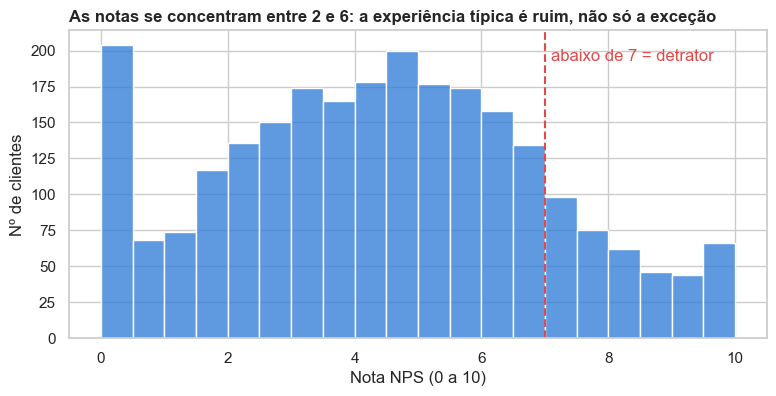

In [3]:
# Histograma das notas: onde os clientes se concentram
figura, eixo = plt.subplots(figsize=(9, 4))
sns.histplot(dados["nps_score"], bins=20, color=COR_AZUL, ax=eixo)
eixo.axvline(7, color=COR_VERMELHA, linestyle="--")
eixo.text(7.1, eixo.get_ylim()[1] * 0.9, "abaixo de 7 = detrator", color=COR_VERMELHA)
eixo.set_title("As notas se concentram entre 2 e 6: a experiência típica é ruim, não só a exceção")
eixo.set_xlabel("Nota NPS (0 a 10)")
eixo.set_ylabel("Nº de clientes")
salvar_figura(figura, "02_histograma_notas.png")
plt.show()

### 1.1 Quão confiável é esse NPS? (intervalo de confiança)

Os 2.500 pedidos são uma **amostra** dos clientes da empresa. Seguindo a Aula 1 de Estatística:

- para o **NPS**, que não segue distribuição normal, usamos o **bootstrap** (reamostragem com reposição);
- para a **proporção de detratores**, usamos o **intervalo de Wilson**, o mais indicado para proporções.

In [4]:
limite_inferior_nps, limite_superior_nps = intervalo_confianca_nps_bootstrap(dados["nps_score"])
print(f"NPS: {nps_da_base:.1f}  |  IC 95% (bootstrap): {limite_inferior_nps:.1f} a {limite_superior_nps:.1f}")

quantidade_detratores = int(dados["e_detrator"].sum())
limite_inferior_det, limite_superior_det = proportion_confint(quantidade_detratores, len(dados), alpha=0.05, method="wilson")
print(f"% de detratores: {100 * quantidade_detratores / len(dados):.1f}%  |  IC 95% (Wilson): "
      f"{100 * limite_inferior_det:.1f}% a {100 * limite_superior_det:.1f}%")

NPS: -80.0  |  IC 95% (bootstrap): -81.8 a -78.0
% de detratores: 84.4%  |  IC 95% (Wilson): 82.9% a 85.7%


**O que isso significa para a operação:** mesmo considerando a margem de erro da amostra, o NPS fica entre aproximadamente −82 e −78, e a proporção de detratores entre 83% e 86%. O problema **não é fruto do acaso nem de um pequeno grupo de clientes irritados**: a nota típica está em torno de 4. Ele é **estrutural**, está no "jeito padrão" como os pedidos são entregues e atendidos.

## 2. Quais fatores parecem mais críticos?

### 2.1 Matriz de correlação

Primeiro, uma visão de todas as variáveis numéricas ao mesmo tempo (correlação de Pearson, de −1 a +1).

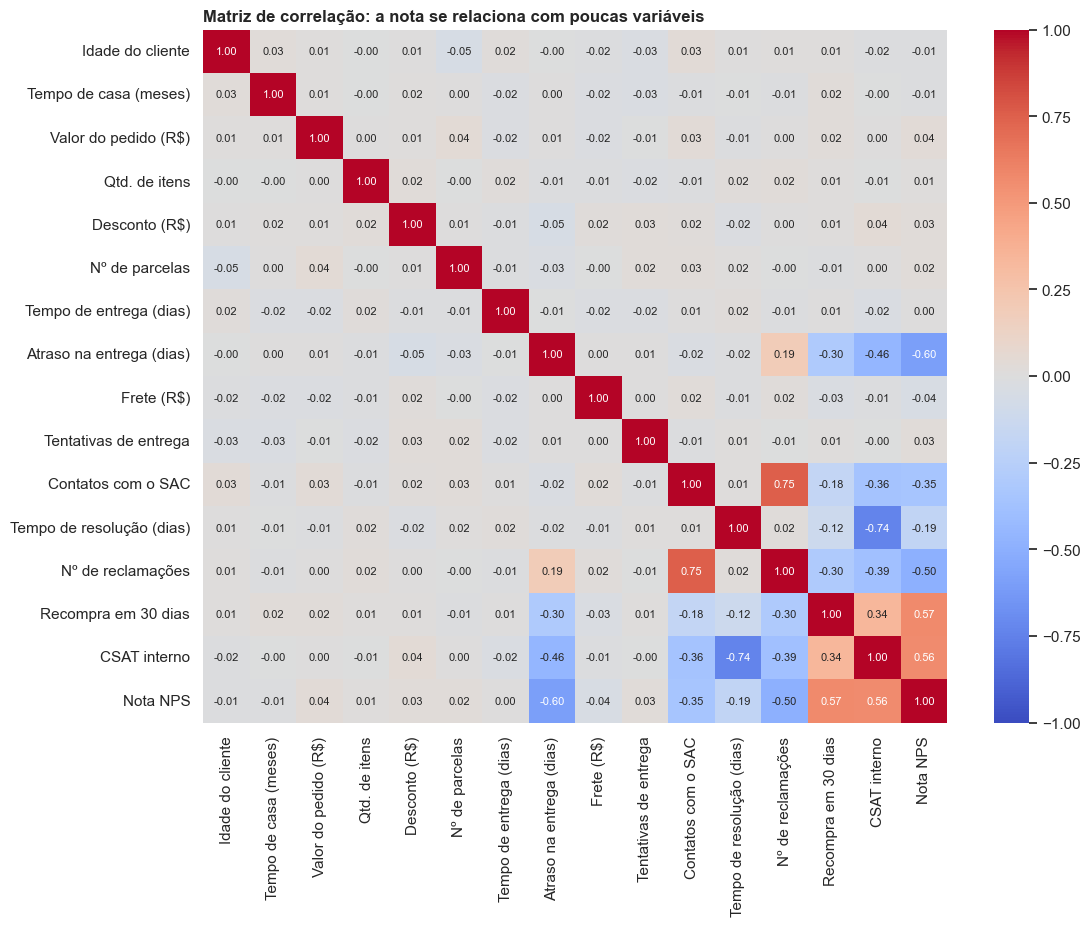

In [5]:
colunas_numericas = [c for c in COLUNAS_PRE_PESQUISA if c != "customer_region"] + COLUNAS_POS_PESQUISA + ["nps_score"]
matriz_correlacao = dados[colunas_numericas].corr().rename(index=NOMES_AMIGAVEIS, columns=NOMES_AMIGAVEIS)

figura, eixo = plt.subplots(figsize=(12, 9))
sns.heatmap(matriz_correlacao, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=eixo, annot_kws={"fontsize": 8})
eixo.set_title("Matriz de correlação: a nota se relaciona com poucas variáveis")
salvar_figura(figura, "03a_matriz_correlacao.png")
plt.show()

Na última linha (Nota NPS) quase tudo é próximo de zero, com exceção de **atraso, reclamações, contatos com o SAC e tempo de resolução** (negativos) e das variáveis de pós-pesquisa (CSAT e recompra, positivas). Entre as próprias variáveis, quase todas as correlações são próximas de zero, com duas exceções importantes:

- **Contatos com o SAC × nº de reclamações (0,75):** andam juntos, são duas faces do mesmo fenômeno ("o cliente teve um problema e precisou acionar a empresa"). No modelo isso pede atenção à **multicolinearidade** (Aula 3 de Estatística): o peso de cada uma pode "dividir" o efeito com a outra;
- **CSAT interno × tempo de resolução (−0,74):** sugere que o CSAT é medido no atendimento. Mais um motivo para não usá-lo como alvo nem como variável do modelo.

### 2.2 Força da relação com a nota (Spearman)

Como a nota e várias variáveis não seguem distribuição normal e têm muitos valores repetidos, confirmamos com a **correlação de Spearman** (Aula 3 de Estatística), que usa a ordem dos valores e é mais resistente a outliers. O p-valor indica se a relação poderia ser fruto do acaso (H₀: não há relação).

In [6]:
tabela_correlacao = []
for coluna in colunas_numericas[:-1]:
    rho, p_valor = stats.spearmanr(dados[coluna], dados["nps_score"])
    tabela_correlacao.append({
        "variavel": coluna,
        "fator": NOMES_AMIGAVEIS[coluna],
        "correlacao_spearman": rho,
        "p_valor": p_valor,
        "grupo": "Pós-pesquisa" if coluna in COLUNAS_POS_PESQUISA else "Operacional (antes da pesquisa)",
    })
tabela_correlacao = pd.DataFrame(tabela_correlacao).sort_values("correlacao_spearman", key=abs, ascending=False)
tabela_correlacao["relacao_significativa (p<0,05)"] = tabela_correlacao["p_valor"] < 0.05
tabela_correlacao.round(3)

,variavel,fator,correlacao_spearman,p_valor,grupo,"relacao_significativa (p<0,05)"
7,delivery_delay_days,Atraso na entrega (dias),-0.586,0.000,Operacional (antes da pesquisa),True
14,csat_internal_score,CSAT interno,0.561,0.000,Pós-pesquisa,True
12,complaints_count,Nº de reclamações,-0.490,0.000,Operacional (antes da pesquisa),True
13,repeat_purchase_30d,Recompra em 30 dias,0.489,0.000,Pós-pesquisa,True
10,customer_service_contacts,Contatos com o SAC,-0.336,0.000,Operacional (antes da pesquisa),True
11,resolution_time_days,Tempo de resolução (dias),-0.190,0.000,Operacional (antes da pesquisa),True
8,freight_value,Frete (R$),-0.040,0.048,Operacional (antes da pesquisa),True
2,order_value,Valor do pedido (R$),0.036,0.073,Operacional (antes da pesquisa),False
5,payment_installments,Nº de parcelas,0.027,0.183,Operacional (antes da pesquisa),False
9,delivery_attempts,Tentativas de entrega,0.026,0.189,Operacional (antes da pesquisa),False


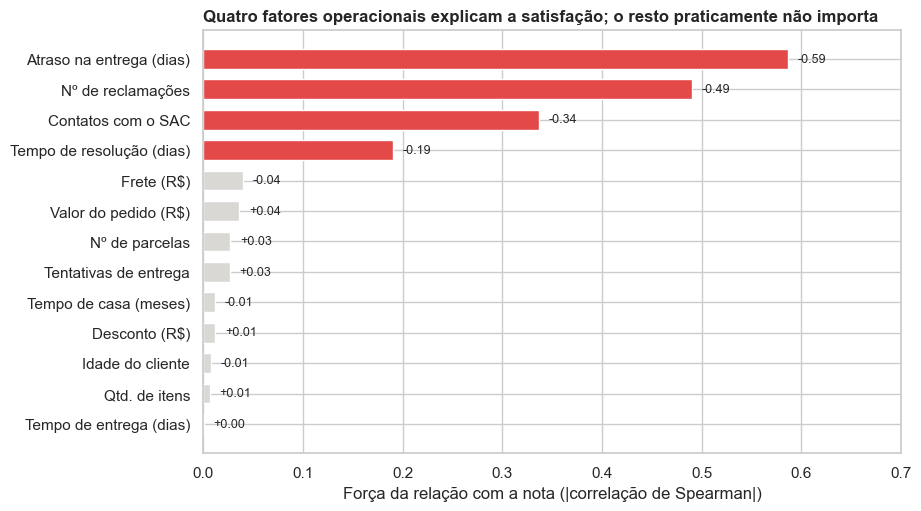

In [7]:
# Gráfico só com os fatores operacionais (os que a empresa controla ANTES da pesquisa)
operacionais = tabela_correlacao[tabela_correlacao["grupo"].str.startswith("Operacional")].sort_values("correlacao_spearman", key=abs)
cores = [COR_VERMELHA if abs(r) >= 0.15 else COR_CINZA_CLARO for r in operacionais["correlacao_spearman"]]

figura, eixo = plt.subplots(figsize=(9, 5.5))
eixo.barh(operacionais["fator"], operacionais["correlacao_spearman"].abs(), color=cores, height=0.65)
for posicao, valor in enumerate(operacionais["correlacao_spearman"]):
    eixo.text(abs(valor) + 0.01, posicao, f"{valor:+.2f}", va="center", fontsize=9)
eixo.set_title("Quatro fatores operacionais explicam a satisfação; o resto praticamente não importa")
eixo.set_xlabel("Força da relação com a nota (|correlação de Spearman|)")
eixo.set_xlim(0, 0.7)
salvar_figura(figura, "03_forca_dos_fatores.png")
plt.show()

**Leitura para o negócio:**

- **Atraso na entrega** é, de longe, o fator nº 1;
- Em seguida vêm três fatores de **atendimento**: nº de reclamações, contatos com o SAC e tempo de resolução;
- **Valor do pedido, frete, desconto, parcelas, itens, tentativas de entrega, idade e tempo de casa praticamente não se relacionam com a nota.** (O frete aparece como "significativo" pelo p-valor, mas a força é de apenas 0,04: com 2.500 pedidos, até efeitos minúsculos ficam significativos. **Significância estatística não é o mesmo que importância prática.**)

> Lembrete das aulas: **correlação não é causalidade**. Os gráficos a seguir aprofundam cada fator, mas a prova de causa só viria de um experimento controlado (teste A/B).

## 3. O fator nº 1: atraso na entrega e o ponto de ruptura (H1)

In [8]:
resumo_por_dia_de_atraso = resumir_nps_por_grupo(dados, "delivery_delay_days")
resumo_por_dia_de_atraso

,pedidos,nota_media,pct_detratores,pct_promotores,nps
delivery_delay_days,,,,,
0,277,6.9,51.6,18.1,-33.6
1,615,5.5,74.0,7.2,-66.8
2,646,4.6,87.9,2.0,-85.9
3,525,3.4,96.8,0.6,-96.2
4,270,2.4,99.3,0.0,-99.3
5,116,1.5,100.0,0.0,-100.0
6,34,1.1,100.0,0.0,-100.0
7,14,0.3,100.0,0.0,-100.0
8,3,0.0,100.0,0.0,-100.0


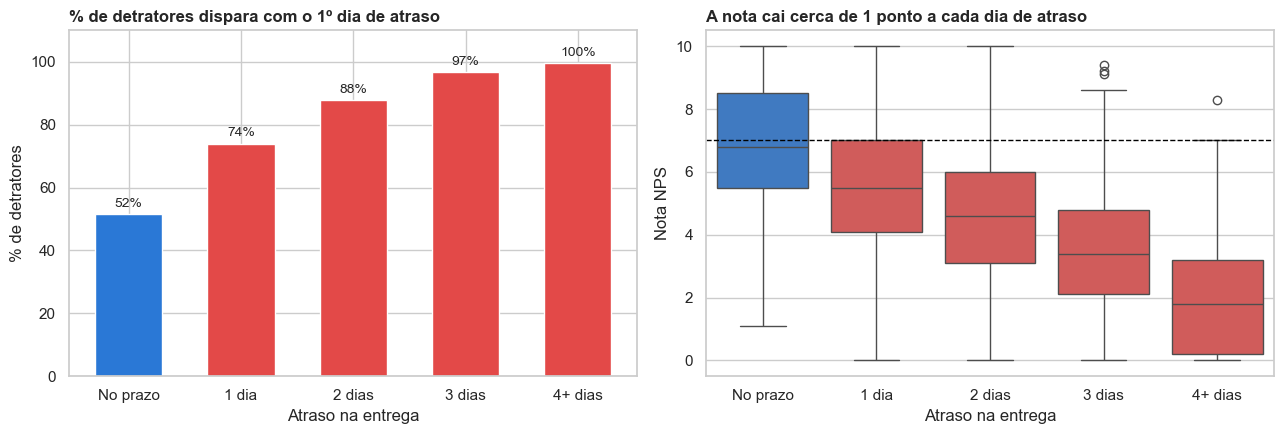

In [9]:
resumo_atraso = resumir_nps_por_grupo(dados, "faixa_atraso")

figura, eixos = plt.subplots(1, 2, figsize=(13, 4.5))

# Painel 1: % de detratores por faixa de atraso
eixos[0].bar(resumo_atraso.index.astype(str), resumo_atraso["pct_detratores"],
             color=[COR_AZUL] + [COR_VERMELHA] * 4, width=0.6)
rotular_barras(eixos[0], sufixo="%")
eixos[0].set_ylim(0, 110)
eixos[0].set_title("% de detratores dispara com o 1º dia de atraso")
eixos[0].set_ylabel("% de detratores")
eixos[0].set_xlabel("Atraso na entrega")

# Painel 2: distribuição das notas por faixa de atraso (boxplot)
sns.boxplot(data=dados, x="faixa_atraso", y="nps_score", ax=eixos[1],
            palette=[COR_AZUL] + [COR_VERMELHA] * 4, hue="faixa_atraso", legend=False)
eixos[1].axhline(7, color="black", linestyle="--", linewidth=1)
eixos[1].set_title("A nota cai cerca de 1 ponto a cada dia de atraso")
eixos[1].set_ylabel("Nota NPS")
eixos[1].set_xlabel("Atraso na entrega")

figura.tight_layout()
salvar_figura(figura, "04_atraso_ponto_de_ruptura.png")
plt.show()

In [10]:
# Teste de hipótese (Mann-Whitney, pois as notas não seguem distribuição normal)
# H0: as notas de quem recebeu no prazo e de quem recebeu com atraso têm a mesma distribuição
# H1: as distribuições são diferentes
notas_no_prazo = dados.loc[dados["entregue_no_prazo"] == 1, "nps_score"]
notas_com_atraso = dados.loc[dados["entregue_no_prazo"] == 0, "nps_score"]
estatistica_u, p_valor = stats.mannwhitneyu(notas_no_prazo, notas_com_atraso)
print(f"Nota média no prazo: {notas_no_prazo.mean():.2f} | com atraso: {notas_com_atraso.mean():.2f}")
print(f"Mann-Whitney U = {estatistica_u:.0f} | p-valor = {p_valor:.2e} -> "
      f"{'rejeitamos H0: o atraso está associado a notas menores' if p_valor < 0.05 else 'não rejeitamos H0'}")

Nota média no prazo: 6.86 | com atraso: 4.07
Mann-Whitney U = 497578 | p-valor = 5.87e-63 -> rejeitamos H0: o atraso está associado a notas menores


**Este é o principal "ponto de ruptura" da experiência (H1 confirmada):**

- Pedido **entregue no prazo**: nota média ~6,9 e ~18% de promotores;
- **1 dia de atraso** já leva 3 em cada 4 clientes para a zona de detrator;
- A partir de **3 dias de atraso**, praticamente **todo** cliente vira detrator (≥ 97%) e nenhum vira promotor.

O atraso não é um incômodo gradual: **o primeiro dia já quebra a confiança, e o terceiro torna a recuperação quase impossível**. A janela para agir é antes do atraso ou, no máximo, nas primeiras 24-48h.

### 3.1 Prazo longo × promessa quebrada (H3)

"Clientes com entrega mais demorada ficam mais insatisfeitos?" Comparamos o **tempo total de entrega** com o **atraso** em relação ao prometido.

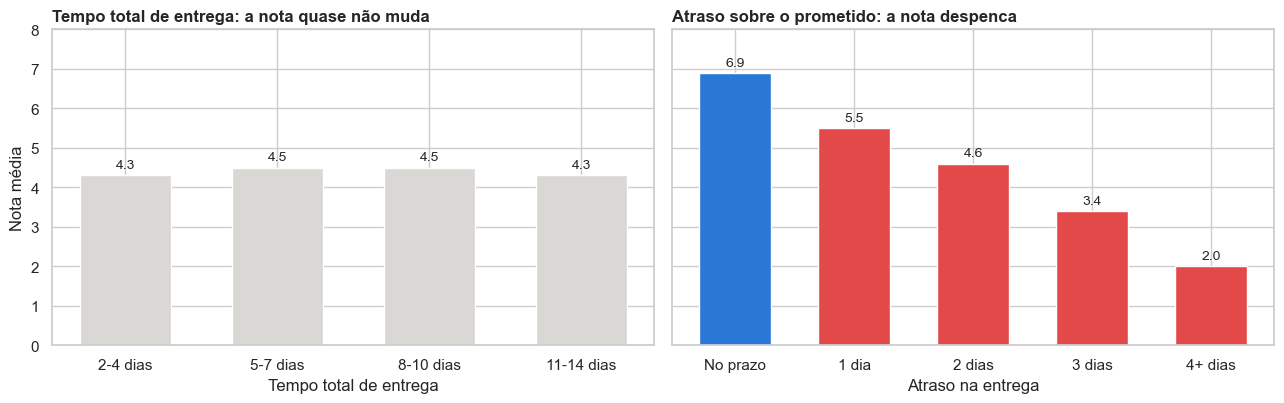

,pedidos,nota_media,pct_detratores,pct_promotores,nps
faixa_tempo_entrega,,,,,
2-4 dias,590,4.3,84.7,4.6,-80.2
5-7 dias,548,4.5,85.6,4.2,-81.4
8-10 dias,571,4.5,83.5,4.9,-78.6
11-14 dias,791,4.3,83.8,4.0,-79.8


In [11]:
dados["faixa_tempo_entrega"] = pd.cut(dados["delivery_time_days"], bins=[1, 4, 7, 10, 14],
                                      labels=["2-4 dias", "5-7 dias", "8-10 dias", "11-14 dias"])
resumo_tempo_entrega = resumir_nps_por_grupo(dados, "faixa_tempo_entrega")

figura, eixos = plt.subplots(1, 2, figsize=(13, 4.2), sharey=True)
eixos[0].bar(resumo_tempo_entrega.index.astype(str), resumo_tempo_entrega["nota_media"], color=COR_CINZA_CLARO, width=0.6)
rotular_barras(eixos[0], formato="{:.1f}")
eixos[0].set_title("Tempo total de entrega: a nota quase não muda")
eixos[0].set_xlabel("Tempo total de entrega")
eixos[0].set_ylabel("Nota média")

eixos[1].bar(resumo_atraso.index.astype(str), resumo_atraso["nota_media"], color=[COR_AZUL] + [COR_VERMELHA] * 4, width=0.6)
rotular_barras(eixos[1], formato="{:.1f}")
eixos[1].set_title("Atraso sobre o prometido: a nota despenca")
eixos[1].set_xlabel("Atraso na entrega")
eixos[0].set_ylim(0, 8)
figura.tight_layout()
salvar_figura(figura, "05_prazo_vs_atraso.png")
plt.show()
resumo_tempo_entrega

**H3 refutada.** Um cliente que recebe em 12 dias *dentro do prazo prometido* fica tão satisfeito quanto um que recebe em 3 dias (correlação de Spearman = 0,00). **O que destrói a satisfação não é a demora, é a quebra da expectativa.** Isso abre uma alavanca de baixo custo: **prometer prazos realistas** (com folga) pode reduzir atrasos sem precisar acelerar a operação.

## 4. Atendimento: reclamações, contatos e tempo de resolução (H2)

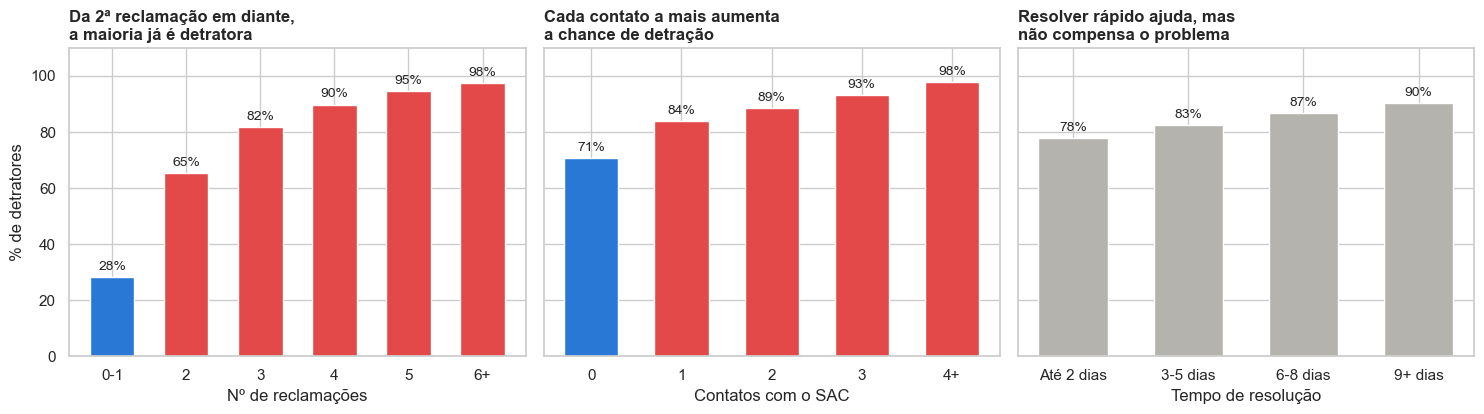

pedidos  nota_media  pct_detratores  \
Reclamações     0-1             145         7.9            28.3   
                2               277         6.1            65.3   
                3               507         4.9            81.7   
                4               600         4.2            89.8   
                5               444         3.6            94.6   
                6+              527         2.8            97.5   
Contatos SAC    0               554         5.5            70.8   
                1               816         4.7            83.9   
                2               640         4.1            88.6   
                3               314         3.2            93.3   
                4+              176         2.5            97.7   
Tempo resolução Até 2 dias      629         5.0            77.7   
                3-5 dias        619         4.5            82.6   
                6-8 dias        637         4.2            86.8   
                9+ dias         615         3.8            90.4   

                            pct_promotores   nps  
Reclamações     0-1                   24.1  -4.1  
                2                     11.2 -54.2  
                3                      4.5 -77.1  
                4                      2.8 -87.0  
                5                      0.7 -93.9  
                6+                     0.2 -97.3  
Contatos SAC    0                     10.3 -60.5  
                1                      4.4 -79.5  
                2                      2.2 -86.4  
                3                      0.6 -92.7  
                4+                     0.6 -97.2  
Tempo resolução Até 2 dias             7.5 -70.3  
                3-5 dias               5.2 -77.4  
                6-8 dias               3.0 -83.8  
                9+ dias                2.0 -88.5

In [12]:
resumo_reclamacoes = resumir_nps_por_grupo(dados, "faixa_reclamacoes")
resumo_contatos = resumir_nps_por_grupo(dados, "faixa_contatos")
resumo_resolucao = resumir_nps_por_grupo(dados, "faixa_resolucao")

figura, eixos = plt.subplots(1, 3, figsize=(15, 4.3), sharey=True)
paineis = [
    (resumo_reclamacoes, "Nº de reclamações", "Da 2ª reclamação em diante,\na maioria já é detratora", [COR_AZUL] + [COR_VERMELHA] * 5),
    (resumo_contatos, "Contatos com o SAC", "Cada contato a mais aumenta\na chance de detração", [COR_AZUL] + [COR_VERMELHA] * 4),
    (resumo_resolucao, "Tempo de resolução", "Resolver rápido ajuda, mas\nnão compensa o problema", [COR_CINZA] * 4),
]
for eixo, (resumo, rotulo_x, titulo, cores) in zip(eixos, paineis):
    eixo.bar(resumo.index.astype(str), resumo["pct_detratores"], color=cores, width=0.6)
    rotular_barras(eixo, sufixo="%")
    eixo.set_title(titulo, fontsize=12)
    eixo.set_xlabel(rotulo_x)
eixos[0].set_ylabel("% de detratores")
eixos[0].set_ylim(0, 110)
figura.tight_layout()
salvar_figura(figura, "06_atendimento.png")
plt.show()
pd.concat({"Reclamações": resumo_reclamacoes, "Contatos SAC": resumo_contatos, "Tempo resolução": resumo_resolucao})

**H2 confirmada.**

- **Reclamações:** com 0-1 reclamação, a nota média fica perto de 8; com **2 reclamações**, 65% já são detratores; com **4 ou mais**, 90%+. É o **segundo ponto de ruptura** da jornada;
- **Contatos com o SAC:** cada contato adicional piora o quadro: com 3 ou mais contatos, mais de 90% são detratores. **Cada contato é um sinal de que algo não foi resolvido de primeira**;
- **Tempo de resolução:** efeito mais suave: resolver em até 2 dias tem ~78% de detratores contra ~90% acima de 8 dias. Ajuda, mas é a **causa** do contato (o atraso, o problema) que mais pesa.

## 5. Quando os problemas se somam

O mapa abaixo cruza os dois fatores mais fortes, **atraso** e **reclamações** (uma tabela cruzada, como o `pd.crosstab` visto em aula, mas com a nota média em cada célula). Vermelho = nota baixa; azul = nota alta; branco ≈ nota 7, a fronteira do detrator.

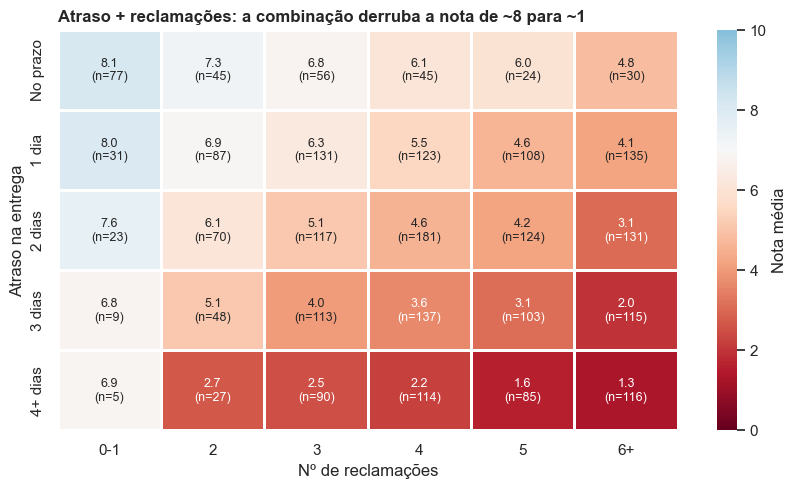

In [13]:
nota_media_cruzada = dados.pivot_table(index="faixa_atraso", columns="faixa_reclamacoes", values="nps_score", aggfunc="mean", observed=False)
pedidos_cruzados = pd.crosstab(dados["faixa_atraso"], dados["faixa_reclamacoes"])
anotacoes = nota_media_cruzada.round(1).astype(str) + "\n(n=" + pedidos_cruzados.astype(str) + ")"

figura, eixo = plt.subplots(figsize=(10, 5.2))
sns.heatmap(nota_media_cruzada, annot=anotacoes, fmt="", cmap="RdBu", center=7, vmin=0, vmax=10,
            linewidths=2, linecolor="white", cbar_kws={"label": "Nota média"}, ax=eixo, annot_kws={"fontsize": 9})
eixo.set_title("Atraso + reclamações: a combinação derruba a nota de ~8 para ~1")
eixo.set_xlabel("Nº de reclamações")
eixo.set_ylabel("Atraso na entrega")
salvar_figura(figura, "07_heatmap_atraso_reclamacoes.png")
plt.show()

Os efeitos **se somam**: no canto "no prazo + 0-1 reclamação" a nota média é ~8; no canto oposto ("4+ dias de atraso + 6+ reclamações") cai para ~1. Também fica claro que **é possível compensar parcialmente um atraso** quando ele não vira reclamação: pedidos com 1 dia de atraso e 0-1 reclamação ainda têm nota ~8. Isso sugere que **comunicar o atraso proativamente** (antes de o cliente reclamar) pode preservar a satisfação.

### 5.1 A "jornada sem atritos"

In [14]:
# Jornada sem atritos: entregue no prazo, no máximo 1 reclamação e no máximo 1 contato com o SAC
sem_atritos = (dados["delivery_delay_days"] == 0) & (dados["complaints_count"] <= 1) & (dados["customer_service_contacts"] <= 1)
dados["tipo_jornada"] = np.where(sem_atritos, "Sem atritos",
                                 np.where(dados["delivery_delay_days"] >= 3, "Atraso de 3+ dias", "Demais pedidos"))
ordem_jornadas = ["Sem atritos", "Demais pedidos", "Atraso de 3+ dias"]
resumir_nps_por_grupo(dados, "tipo_jornada").loc[ordem_jornadas]

,pedidos,nota_media,pct_detratores,pct_promotores,nps
tipo_jornada,,,,,
Sem atritos,77,8.1,24.7,33.8,9.1
Demais pedidos,1461,5.2,78.5,5.5,-73.0
Atraso de 3+ dias,962,2.8,98.0,0.3,-97.7


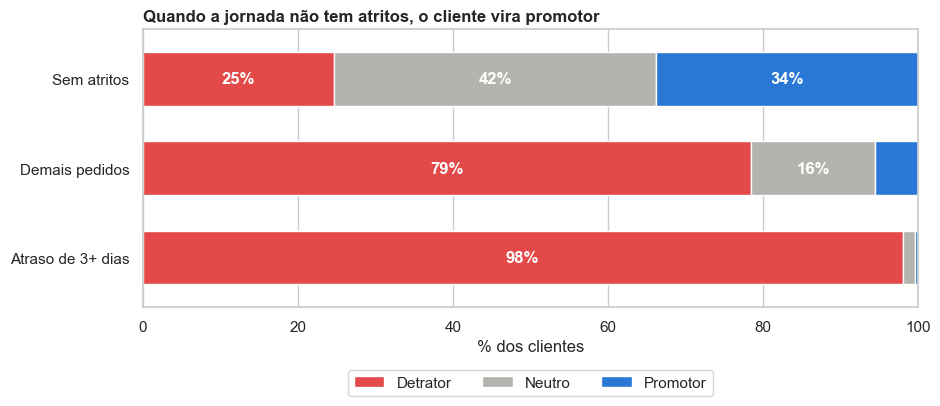

In [15]:
# Composição (barras empilhadas a partir de uma tabela cruzada normalizada por linha)
composicao = pd.crosstab(dados["tipo_jornada"], dados["categoria_nps"], normalize="index").loc[ordem_jornadas] * 100

figura, eixo = plt.subplots(figsize=(10, 3.6))
composicao.plot(kind="barh", stacked=True, ax=eixo, width=0.6,
                color=[CORES_CATEGORIA_NPS[c] for c in composicao.columns], edgecolor="white")
for grupo_de_barras in eixo.containers:
    eixo.bar_label(grupo_de_barras, labels=[f"{v:.0f}%" if v >= 6 else "" for v in grupo_de_barras.datavalues],
                   label_type="center", color="white", fontweight="bold")
eixo.invert_yaxis()
eixo.set_xlim(0, 100)
eixo.set_xlabel("% dos clientes")
eixo.set_ylabel("")
eixo.legend(title="", ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.2))
eixo.set_title("Quando a jornada não tem atritos, o cliente vira promotor")
salvar_figura(figura, "08_jornada_sem_atritos.png")
plt.show()

Pedidos **sem atritos** (no prazo, ≤ 1 reclamação e ≤ 1 contato) têm um perfil completamente diferente: nota média ~8, NPS positivo e mais promotores que detratores. É um grupo pequeno (77 pedidos, ~3% da base), o que por si só é um achado: **a jornada ideal é rara hoje**. Já pedidos com **3+ dias de atraso** praticamente não geram promotores.

## 6. Que tipo de cliente tem NPS mais alto ou mais baixo? (H5)

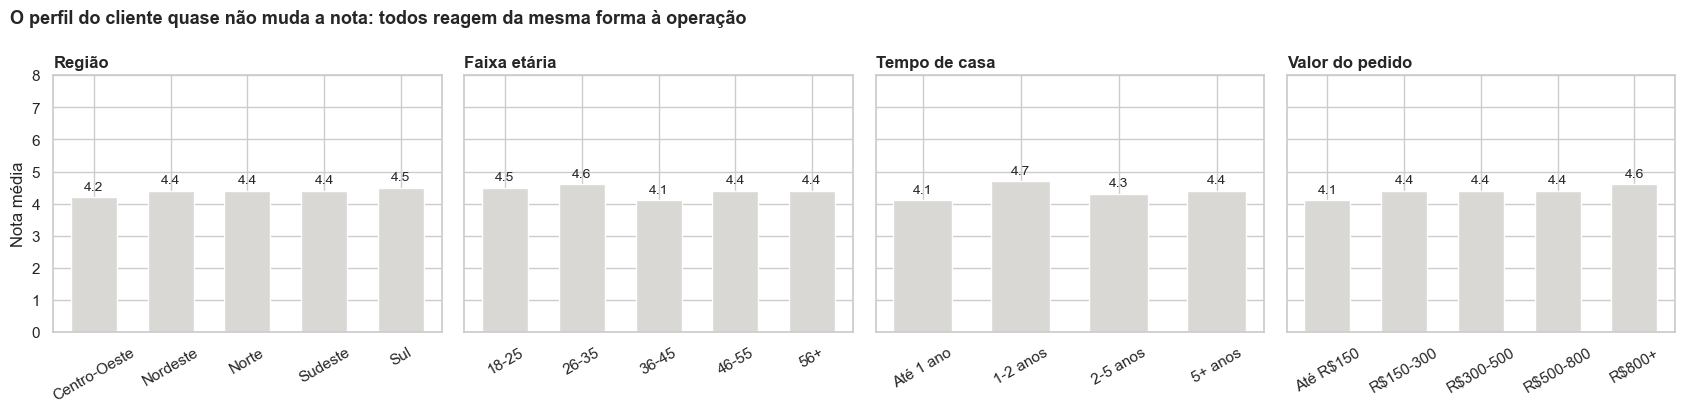

In [16]:
dimensoes_de_perfil = {
    "Região": "customer_region",
    "Faixa etária": "faixa_idade",
    "Tempo de casa": "faixa_tempo_casa",
    "Valor do pedido": "faixa_valor_pedido",
}
figura, eixos = plt.subplots(1, 4, figsize=(17, 4.2), sharey=True)
for eixo, (titulo, coluna) in zip(eixos, dimensoes_de_perfil.items()):
    resumo = resumir_nps_por_grupo(dados, coluna)
    eixo.bar(resumo.index.astype(str), resumo["nota_media"], color=COR_CINZA_CLARO, width=0.6)
    rotular_barras(eixo, formato="{:.1f}")
    eixo.set_title(titulo, fontsize=12)
    eixo.tick_params(axis="x", rotation=30)
eixos[0].set_ylabel("Nota média")
eixos[0].set_ylim(0, 8)
figura.suptitle("O perfil do cliente quase não muda a nota: todos reagem da mesma forma à operação",
                x=0.01, ha="left", fontweight="bold", fontsize=13)
figura.tight_layout()
salvar_figura(figura, "09_perfil_cliente.png")
plt.show()

In [17]:
# Kruskal-Wallis (alternativa à ANOVA quando não há normalidade), um teste por dimensão
# H0: a distribuição das notas é a mesma em todos os grupos daquela dimensão
resultados_testes = []
for titulo, coluna in dimensoes_de_perfil.items():
    notas_por_grupo = [grupo["nps_score"].values for _, grupo in dados.groupby(coluna, observed=True)]
    estatistica_h, p_valor = stats.kruskal(*notas_por_grupo)
    resultados_testes.append({"dimensão": titulo, "teste": "Kruskal-Wallis", "p_valor": round(p_valor, 3),
                              "conclusão": "rejeita H0" if p_valor < 0.05 else "não rejeita H0 (sem diferença)"})

# Qui-quadrado (variáveis categóricas): a proporção de detratores/neutros/promotores muda entre regiões?
# H0: região e categoria NPS são independentes
tabela_regiao = pd.crosstab(dados["customer_region"], dados["categoria_nps"])
qui2, p_valor, graus_liberdade, _ = stats.chi2_contingency(tabela_regiao)
resultados_testes.append({"dimensão": "Região × categoria NPS", "teste": "Qui-quadrado", "p_valor": round(p_valor, 3),
                          "conclusão": "rejeita H0" if p_valor < 0.05 else "não rejeita H0 (sem diferença)"})
pd.DataFrame(resultados_testes)

,dimensão,teste,p_valor,conclusão
0,Região,Kruskal-Wallis,0.497,não rejeita H0 (sem diferença)
1,Faixa etária,Kruskal-Wallis,0.107,não rejeita H0 (sem diferença)
2,Tempo de casa,Kruskal-Wallis,0.187,não rejeita H0 (sem diferença)
3,Valor do pedido,Kruskal-Wallis,0.230,não rejeita H0 (sem diferença)
4,Região × categoria NPS,Qui-quadrado,0.898,não rejeita H0 (sem diferença)


**H5 refutada.** Região, idade, tempo de relacionamento e valor do pedido **não** separam clientes satisfeitos de insatisfeitos: as diferenças são de décimos de ponto e nenhum teste rejeita a hipótese nula.

Isso responde à pergunta "que tipo de cliente tem NPS mais alto ou mais baixo?" de forma talvez surpreendente: **não é o tipo de cliente, é o tipo de experiência.** O cliente com NPS alto é aquele que recebeu **no prazo**, **não precisou reclamar** (ou reclamou no máximo uma vez) e **resolveu tudo com até 1 contato**. O cliente com NPS baixo passou por **atraso + reclamações + idas e vindas com o SAC**, em qualquer região ou faixa etária.

> **Implicação prática:** segmentar ações de CX por perfil demográfico teria pouco efeito. As ações devem ser **segmentadas pela situação operacional do pedido**, informação disponível *antes* da pesquisa de NPS.

## 7. Fatores que **não** fazem diferença (H4)

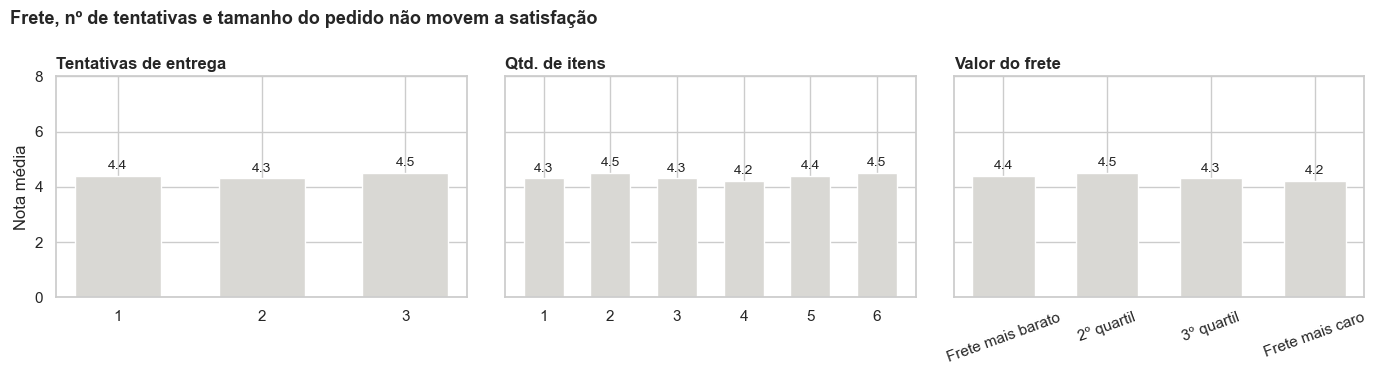

In [18]:
figura, eixos = plt.subplots(1, 3, figsize=(14, 3.8), sharey=True)
for eixo, (titulo, coluna) in zip(eixos[:2], {"Tentativas de entrega": "delivery_attempts", "Qtd. de itens": "items_quantity"}.items()):
    resumo = resumir_nps_por_grupo(dados, coluna)
    eixo.bar(resumo.index.astype(str), resumo["nota_media"], color=COR_CINZA_CLARO, width=0.6)
    rotular_barras(eixo, formato="{:.1f}")
    eixo.set_title(titulo, fontsize=12)

dados["faixa_frete"] = pd.qcut(dados["freight_value"], 4, labels=["Frete mais barato", "2º quartil", "3º quartil", "Frete mais caro"])
resumo = resumir_nps_por_grupo(dados, "faixa_frete")
eixos[2].bar(resumo.index.astype(str), resumo["nota_media"], color=COR_CINZA_CLARO, width=0.6)
rotular_barras(eixos[2], formato="{:.1f}")
eixos[2].set_title("Valor do frete", fontsize=12)
eixos[2].tick_params(axis="x", rotation=20)
eixos[0].set_ylabel("Nota média")
eixos[0].set_ylim(0, 8)
figura.suptitle("Frete, nº de tentativas e tamanho do pedido não movem a satisfação", x=0.01, ha="left", fontweight="bold", fontsize=13)
figura.tight_layout()
salvar_figura(figura, "10_fatores_sem_impacto.png")
plt.show()

**H4 refutada.**

- **Frete mais caro não gera mais detratores**: baixar frete ou dar frete grátis para "comprar" satisfação tende a ter retorno baixo;
- **Descontos e parcelamento** também não se relacionam com a nota (seção 2): não usar cupom como principal ferramenta de recuperação;
- **Tentativas de entrega** não afetam a nota: o cliente parece se importar com a *data* em que recebe, não com quantas vezes o entregador passou.

Saber o que **não** funciona evita gastar orçamento nas alavancas erradas.

## 8. Registro das descobertas

No formato sugerido na Aula 2 de EDA (observação → evidência → hipótese → próximos passos):

| Observação | Evidência | Hipótese / interpretação | Próximos passos |
|---|---|---|---|
| O 1º dia de atraso derruba a satisfação | No prazo: 52% detratores; 1 dia: 74%; 3+ dias: ≥ 97% (Mann-Whitney p < 0,001) | A quebra da promessa de entrega é o principal gatilho de detração | Testar aviso proativo de atraso e prazos com folga, com grupo de controle |
| O tempo total de entrega não importa | Nota média 4,3-4,5 em todas as faixas de prazo; Spearman = 0,00 | O cliente avalia a promessa, não a velocidade | Revisar a regra de cálculo do prazo prometido por região |
| A 2ª reclamação é um ponto de ruptura | 0-1 reclamação: 28% detratores; 2: 65%; 4+: 90%+ | Reclamações repetidas indicam problema não resolvido | Escalonamento automático na 2ª reclamação |
| Problemas se somam | Nota ~8 (no prazo, 0-1 reclamação) contra ~1 (4+ dias e 6+ reclamações) | Atraso sem reclamação ainda preserva a nota | Contato proativo antes da reclamação |
| Perfil do cliente não explica a nota | Kruskal-Wallis e qui-quadrado sem diferença (p > 0,05) | A experiência pesa mais que o perfil | Segmentar ações pela situação do pedido, não por demografia |
| Frete, desconto e valor não importam | Correlações ≈ 0 | Compensações financeiras não "compram" satisfação | Priorizar orçamento em logística e atendimento |

## 9. Respostas às perguntas da etapa 3

| Pergunta | Resposta |
|---|---|
| **Quais fatores são mais críticos?** | 1º **atraso na entrega**; depois **reclamações**, **contatos com o SAC** e **tempo de resolução**. Fatores do pedido (valor, frete, desconto, parcelas) e de perfil (idade, região, tempo de casa) praticamente não influenciam. |
| **O que mais gera detratores?** | Atraso, sobretudo combinado com reclamações. 1 dia de atraso → 74% detratores; 3+ dias → ~100%. 2+ reclamações → maioria detratora. |
| **Existe ponto de ruptura?** | Sim, dois: **o 1º dia de atraso** e **a 2ª reclamação**. A partir de **3 dias de atraso** a recuperação é praticamente impossível. |
| **Que cliente tem NPS mais alto ou mais baixo?** | Não é o perfil demográfico, é a **experiência**: entregue no prazo, sem reclamar e resolvido em até 1 contato → nota alta. Atraso + reclamações + vários contatos → nota baixa, em qualquer região ou idade. |

**Ressalvas:** a análise mostra **associações**, não prova causalidade; a base é um retrato de 2.500 pedidos (um por cliente) e não tem data, canal, categoria de produto nem transportadora, informações que permitiriam ir mais fundo nas causas do atraso.